# Statistical tests and comparison to other methods

In [ ]:
import pandas as pd

In [ ]:
dtype = {col: "category" for col in "scoring_method mlm emb cont_emb ling_category".split()}
df = pd.read_csv("mlm-emb-experiment-results-21-08-26.csv", dtype=dtype)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 648000 entries, 0 to 647999
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   scoring_method  648000 non-null  category
 1   mlm             648000 non-null  category
 2   emb             648000 non-null  category
 3   topk            648000 non-null  int64   
 4   cont_emb        648000 non-null  category
 5   long_cont       648000 non-null  int64   
 6   experiment      648000 non-null  object  
 7   score           648000 non-null  float64 
 8   id              648000 non-null  object  
 9   expectations    648000 non-null  int64   
 10  ling_category   648000 non-null  category
 11  pred            648000 non-null  int64   
 12  correct         648000 non-null  bool    
dtypes: bool(1), category(5), float64(1), int64(4), object(2)
memory usage: 38.3+ MB


In [ ]:
for col in dtype:
  display(df[col].value_counts())
  print()

,count
scoring_method,
hard,324000
soft,324000


,count
mlm,
ModernBERT-base,129600
bert-base-uncased,129600
bert-large-uncased,129600
distilbert-base-uncased,129600
roberta-base,129600


,count
emb,
all-MiniLM-L6-v2,216000
bge-base-en-v1.5,216000
modernbert-embed-base,216000


,count
cont_emb,
contextual,216000
static,216000
template,216000


,count
ling_category,
verb_objects,162000
verb_subjects,162000
adjectives,129600
role_function_NPs,75600
genitive_NPs,64800
comparisons,54000


In [ ]:
df

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,id,expectations,ling_category,pred,correct
0,soft,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.025088,3_acl_7_46407_0,2,adjectives,1,False
1,hard,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,24.672467,3_acl_7_46407_0,2,adjectives,1,False
2,soft,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.036282,3_acl_7_46407_0,2,adjectives,1,False
3,hard,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,1.820348,3_acl_7_46407_0,2,adjectives,1,False
4,soft,distilbert-base-uncased,all-MiniLM-L6-v2,10,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.029241,3_acl_7_46407_0,2,adjectives,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
647995,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,3.645364,1_arx_2010.09890_1366220_2,1,verb_subjects,1,True
647996,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,-1.455433,1_acl_1477_40886_4,1,verb_subjects,0,False
647997,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,-1.920960,1_arx_2303.09387_1809184_9,1,verb_subjects,0,False
647998,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,5.424074,1_arx_2212.01681_1757858_4,1,verb_subjects,1,True


## Compare selected experiments

In [ ]:
# Collect experiments to compare to see if the results
# differ significantly

old_berts = ("bert-base-uncased", "bert-large-uncased", "distilbert-base-uncased")
emb = "all-MiniLM-L6-v2"
min_topk = 50
scoring = "soft"
cont_emb = ["static", "contextual"]
long_cont = 0

mask = ((df["mlm"].isin(old_berts)) & (df["emb"] == emb) &
 (df["topk"] >= min_topk) & (df["scoring_method"] == scoring) &
 (df["cont_emb"].isin(cont_emb)) & (df["long_cont"] == long_cont))

to_compare = df[mask]

In [ ]:
to_compare

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,id,expectations,ling_category,pred,correct
6,soft,distilbert-base-uncased,all-MiniLM-L6-v2,50,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.020428,3_acl_7_46407_0,2,adjectives,1,False
8,soft,distilbert-base-uncased,all-MiniLM-L6-v2,100,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.014483,3_acl_7_46407_0,2,adjectives,1,False
10,soft,distilbert-base-uncased,all-MiniLM-L6-v2,150,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.012079,3_acl_7_46407_0,2,adjectives,1,False
78,soft,bert-base-uncased,all-MiniLM-L6-v2,50,contextual,0,soft_bert-base-uncased_all-MiniLM-L6-v2_k50_co...,0.026557,3_acl_7_46407_0,2,adjectives,1,False
80,soft,bert-base-uncased,all-MiniLM-L6-v2,100,contextual,0,soft_bert-base-uncased_all-MiniLM-L6-v2_k100_c...,0.025442,3_acl_7_46407_0,2,adjectives,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
588595,soft,bert-base-uncased,all-MiniLM-L6-v2,150,static,0,soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,0.116275,1_arx_2010.09890_1366220_2,1,verb_subjects,1,True
588596,soft,bert-base-uncased,all-MiniLM-L6-v2,150,static,0,soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,0.128225,1_acl_1477_40886_4,1,verb_subjects,1,True
588597,soft,bert-base-uncased,all-MiniLM-L6-v2,150,static,0,soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,-0.014918,1_arx_2303.09387_1809184_9,1,verb_subjects,0,False
588598,soft,bert-base-uncased,all-MiniLM-L6-v2,150,static,0,soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,0.213944,1_arx_2212.01681_1757858_4,1,verb_subjects,1,True


In [ ]:
len(to_compare.groupby("experiment", observed=True))

18

In [ ]:
to_compare.experiment.unique()

array(['soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0',
       'soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0',
       'soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0',
       'soft_bert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0',
       'soft_bert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0',
       'soft_bert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0',
       'soft_bert-large-uncased_all-MiniLM-L6-v2_k50_contextual_0',
       'soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0',
       'soft_bert-large-uncased_all-MiniLM-L6-v2_k150_contextual_0',
       'soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_0_0',
       'soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_0_0',
       'soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_0_0',
       'soft_bert-large-uncased_all-MiniLM-L6-v2_k50_0_0',
       'soft_bert-large-uncased_all-MiniLM-L6-v2_k100_0_0',
       'soft_bert-large-uncased_all-MiniLM-L6-v2_k150_0_0

In [ ]:
to_compare.groupby("experiment", observed=True)["correct"].value_counts(normalize=True).unstack("correct")

correct,False,True
experiment,,
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,0.401667,0.598333
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.405000,0.595000
soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,0.401667,0.598333
soft_bert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.405000,0.595000
soft_bert-base-uncased_all-MiniLM-L6-v2_k50_0_0,0.401667,0.598333
soft_bert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,0.405000,0.595000
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_0_0,0.395000,0.605000
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.393333,0.606667
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_0_0,0.395000,0.605000


In [ ]:
to_compare_no_inconclusive = to_compare[to_compare["expectations"] != 2]

In [ ]:
to_compare_no_inconclusive.groupby("experiment", observed=True)["correct"].value_counts(normalize=True).unstack("correct")

correct,False,True
experiment,,
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,0.234542,0.765458
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.238806,0.761194
soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,0.234542,0.765458
soft_bert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.238806,0.761194
soft_bert-base-uncased_all-MiniLM-L6-v2_k50_0_0,0.234542,0.765458
soft_bert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,0.238806,0.761194
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_0_0,0.226013,0.773987
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.223881,0.776119
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_0_0,0.226013,0.773987


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

f1_cats = {'verb_subjects', 'verb_objects', 'adjectives'}
accuracy_cats = {'role_function_NPs', 'genitive_NPs'}

def score_group(g):
    cat = g.ling_category.iloc[0]
    if cat in accuracy_cats:
        return accuracy_score(g.expectations, g.pred)
    else:
        return f1_score(g.expectations, g.pred, average="macro")

In [ ]:
scored = (
    to_compare_no_inconclusive.groupby(["experiment", "ling_category"], observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)
scored

/tmp/ipykernel_3956/539515815.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


,ling_category,performance
experiment,,
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,adjectives,0.745815
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,genitive_NPs,0.800000
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,role_function_NPs,0.771429
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,verb_objects,0.796533
soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,verb_subjects,0.724057
...,...,...
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,adjectives,0.701093
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,genitive_NPs,0.733333
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,role_function_NPs,0.885714


In [ ]:
scored.groupby("experiment", observed=True)["performance"].mean().sort_values(ascending=False)

,performance
experiment,
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.789773
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.785012
soft_bert-large-uncased_all-MiniLM-L6-v2_k50_contextual_0,0.782436
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_0_0,0.782232
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_0_0,0.782232
soft_bert-large-uncased_all-MiniLM-L6-v2_k50_0_0,0.779374
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.773177
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,0.772092
soft_bert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.769788


In [ ]:
scored.groupby("experiment", observed=True)["performance"].mean().sort_values(ascending=False).mean()

np.float64(0.7727815646381324)

Using only the conclusive examples (either contains anthropomophization or does not) (n=469), test with Cochran's Q if the differences in the correct predictions are significant. To do this, pivot the DataFrame to a shape where each experiment (of the chosen subset) is a column, and the rows are the examples from AnthroSet, and the cells recording if the binarized prediction is correct (=equals the annotation in AnthroSet).

In [ ]:
from statsmodels.stats.contingency_tables import cochrans_q

In [ ]:
wide = to_compare_no_inconclusive.pivot(index="id", columns="experiment", values="correct")
wide

experiment,soft_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,soft_bert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0,soft_bert-base-uncased_all-MiniLM-L6-v2_k150_0_0,soft_bert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0,soft_bert-base-uncased_all-MiniLM-L6-v2_k50_0_0,soft_bert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0,soft_bert-large-uncased_all-MiniLM-L6-v2_k100_0_0,soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,soft_bert-large-uncased_all-MiniLM-L6-v2_k150_0_0,soft_bert-large-uncased_all-MiniLM-L6-v2_k150_contextual_0,soft_bert-large-uncased_all-MiniLM-L6-v2_k50_0_0,soft_bert-large-uncased_all-MiniLM-L6-v2_k50_contextual_0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_0_0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_0_0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_contextual_0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_0_0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_contextual_0
id,,,,,,,,,,,,,,,,,,
1_acl_0709.0625_22890_4,False,True,False,True,False,True,False,True,False,True,False,True,True,True,True,True,True,True
1_acl_1023_35862_2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1_acl_110_36259_1,False,True,False,True,False,True,True,True,True,True,True,True,True,True,True,True,True,True
1_acl_11_13818_6,True,True,True,True,True,True,True,True,True,True,True,True,False,False,False,False,True,False
1_acl_1262_36095_8,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5_arx_2310.02417_1924674_0,True,True,True,True,True,True,True,True,True,True,True,True,False,False,True,True,False,False
5_arx_2311.08487_1951454_2,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
5_arx_2405.01576_2058788_0,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


In [ ]:
res = cochrans_q(wide.values)
print(res)

df          17
pvalue      0.9998451093588866
statistic   3.3582089552238807


If all 1080 experiments are compred, they are significantly different.

In [ ]:
df_no_inconclusive = df[df["expectations"] != 2]

In [ ]:
df_wide = df_no_inconclusive.pivot(index="id", columns="experiment", values="correct")
res_all = cochrans_q(df_wide.values)
print(res_all)

df          1079
pvalue      0.0
statistic   11002.315081413371


In [ ]:
df_scored = (
    df_no_inconclusive.groupby(["experiment", "ling_category"], observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)
df_scored

/tmp/ipykernel_3956/1965998981.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


,ling_category,performance
experiment,,
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,adjectives,0.652273
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,genitive_NPs,0.783333
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,role_function_NPs,0.642857
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_objects,0.785427
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_subjects,0.674619
...,...,...
soft_roberta-base_modernbert-embed-base_k5_contextual_1,adjectives,0.585317
soft_roberta-base_modernbert-embed-base_k5_contextual_1,genitive_NPs,0.450000
soft_roberta-base_modernbert-embed-base_k5_contextual_1,role_function_NPs,0.600000


In [ ]:
ranked = df_scored.groupby("experiment", observed=True)["performance"].mean().sort_values(ascending=False).reset_index()
ranked["rank"] = ranked["performance"].rank(ascending=False)
ranked

,experiment,performance,rank
0,soft_bert-large-uncased_all-MiniLM-L6-v2_k150_...,0.789773,1.0
1,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.789213,2.0
2,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.786603,3.5
3,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.786603,3.5
4,soft_bert-large-uncased_all-MiniLM-L6-v2_k100_...,0.785012,5.0
...,...,...,...
1075,soft_roberta-base_all-MiniLM-L6-v2_k1_2_1,0.431329,1075.5
1076,hard_roberta-base_all-MiniLM-L6-v2_k50_2_1,0.425963,1077.0
1077,hard_roberta-base_all-MiniLM-L6-v2_k150_2_1,0.423894,1078.5
1078,hard_roberta-base_all-MiniLM-L6-v2_k100_2_1,0.423894,1078.5


How well does the chosen method rank?

In [ ]:
find = "soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_0_0"
ranked[ranked["experiment"] == find]

,experiment,performance,rank
50,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.760465,51.0


Given that 51/1080=0.0472, the chosen method is within the best 5% of the methods.

<Axes: xlabel='ling_category', ylabel='performance'>

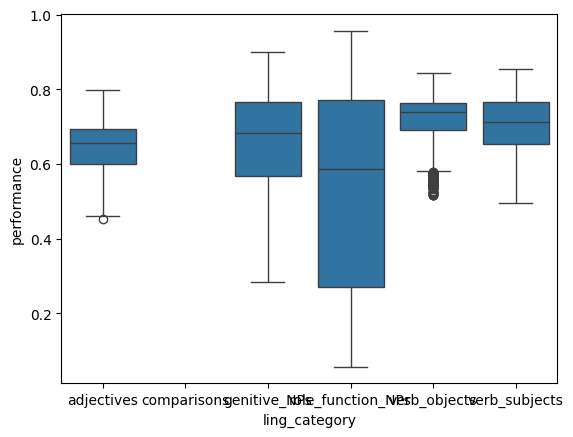

In [ ]:
import seaborn as sns

sns.boxplot(df_scored, x="ling_category", y="performance")

<Axes: xlabel='ling_category', ylabel='performance'>

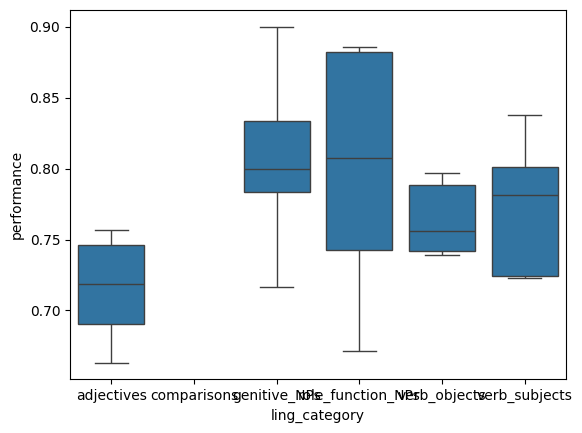

In [ ]:
sns.boxplot(scored, x="ling_category", y="performance")

In [ ]:
df.score.describe()

,score
count,648000.000000
mean,-0.173260
std,9.108331
min,-27.630698
25%,-0.365431
50%,-0.010632
75%,0.107139
max,27.631020


In [ ]:
df[df["experiment"] == find].score.describe()

,score
count,600.000000
mean,0.025176
std,0.071439
min,-0.135885
25%,-0.032505
50%,0.014410
75%,0.087775
max,0.190836


In [ ]:
ranges = df.groupby("topk", observed=True)["score"].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).reset_index()
ranges

,topk,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
0,1,108000.0,-0.242836,16.123871,-27.630578,-27.482318,-26.322621,-20.712832,-18.172350,-0.009706,0.179042,25.680808,26.681241,27.544959,27.631012
1,5,108000.0,-0.391603,10.746625,-27.630698,-27.410029,-20.656020,-19.744279,-0.324228,-0.009843,0.117294,4.888438,26.208424,27.478400,27.631019
2,10,108000.0,-0.353496,8.433139,-27.630521,-27.316298,-20.311281,-4.103741,-0.316930,-0.010218,0.107068,3.010699,19.796092,27.475095,27.631020
3,50,108000.0,-0.079470,4.682433,-27.630128,-20.449737,-4.925517,-3.181172,-0.327571,-0.011161,0.093877,2.382776,3.831067,27.407557,27.631018
4,100,108000.0,0.011990,3.928738,-27.629344,-7.311025,-4.612498,-3.024562,-0.335006,-0.011371,0.090005,2.240915,3.618560,27.364730,27.631019
5,150,108000.0,0.015853,3.696342,-27.629501,-6.970049,-4.474934,-2.948322,-0.340310,-0.011560,0.088079,2.184484,3.527989,27.174502,27.631020


In [ ]:
ranges["std"].corr(ranges["topk"])

np.float64(-0.7875075744815352)

In [ ]:
df.groupby("emb", observed=True)["score"].describe()

,count,mean,std,min,25%,50%,75%,max
emb,,,,,,,,
all-MiniLM-L6-v2,216000.0,-0.273588,8.301339,-27.630698,-0.327788,-0.015833,0.141713,27.631012
bge-base-en-v1.5,216000.0,0.853793,10.342072,-27.630578,-0.065483,0.002957,0.294203,27.631020
modernbert-embed-base,216000.0,-1.099986,8.431573,-27.630359,-1.018548,-0.028542,0.069557,27.631012


## Redraw the context plot

In [ ]:
no_inconclusive = df[df["expectations"] != 2]
scored_all = (
    no_inconclusive.groupby(["experiment", "ling_category"], observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)

/tmp/ipykernel_643/1311614739.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


In [ ]:
cols = [
    "scoring_method",
    "mlm",
    "emb",
    "topk",
    "cont_emb",
    "long_cont"
]
scores_per_experiment = pd.merge(scored_all,
                                 no_inconclusive.drop_duplicates("experiment").set_index("experiment")[cols],
                                 how="left", on="experiment")
scores_per_experiment

,ling_category,performance,scoring_method,mlm,emb,topk,cont_emb,long_cont
experiment,,,,,,,,
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,adjectives,0.652273,hard,ModernBERT-base,all-MiniLM-L6-v2,100,static,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,genitive_NPs,0.783333,hard,ModernBERT-base,all-MiniLM-L6-v2,100,static,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,role_function_NPs,0.642857,hard,ModernBERT-base,all-MiniLM-L6-v2,100,static,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_objects,0.785427,hard,ModernBERT-base,all-MiniLM-L6-v2,100,static,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_subjects,0.674619,hard,ModernBERT-base,all-MiniLM-L6-v2,100,static,0
...,...,...,...,...,...,...,...,...
soft_roberta-base_modernbert-embed-base_k5_contextual_1,adjectives,0.585317,soft,roberta-base,modernbert-embed-base,5,contextual,1
soft_roberta-base_modernbert-embed-base_k5_contextual_1,genitive_NPs,0.450000,soft,roberta-base,modernbert-embed-base,5,contextual,1
soft_roberta-base_modernbert-embed-base_k5_contextual_1,role_function_NPs,0.600000,soft,roberta-base,modernbert-embed-base,5,contextual,1


In [ ]:
cont_emb_map = {0: "static", "contextual": "contextual", 2: "template"}
long_cont_map = {0: "short", 1: "long"}
mlm_map = {'ModernBERT-base': "ModernBERT",
           'bert-base-uncased': "BERT-base",
           'bert-large-uncased': "BERT-large",
           'distilbert-base-uncased': "DistilBERT",
           'roberta-base': "RoBERTa"}

scores_per_experiment["context"] = (scores_per_experiment["cont_emb"].astype(str).replace(cont_emb_map)+ " + " + scores_per_experiment["long_cont"].replace(long_cont_map)).astype("category")
scores_per_experiment["mlm_abb"] = scores_per_experiment["mlm"].astype(str).replace(mlm_map)

In [ ]:
context_order = ['static + short', 'static + long', 'contextual + short', 'contextual + long', 'template + short', 'template + long']

In [ ]:
scores_no_log = scores_per_experiment[scores_per_experiment["scoring_method"] == "soft"].copy()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Group static + short average: 0.6976623446637739
Group static + long average: 0.6859815924604302
Group contextual + short average: 0.7173244259843744
Group contextual + long average: 0.7006048973581218
Group template + short average: 0.6146208757894583
Group template + long average: 0.5540034762646955


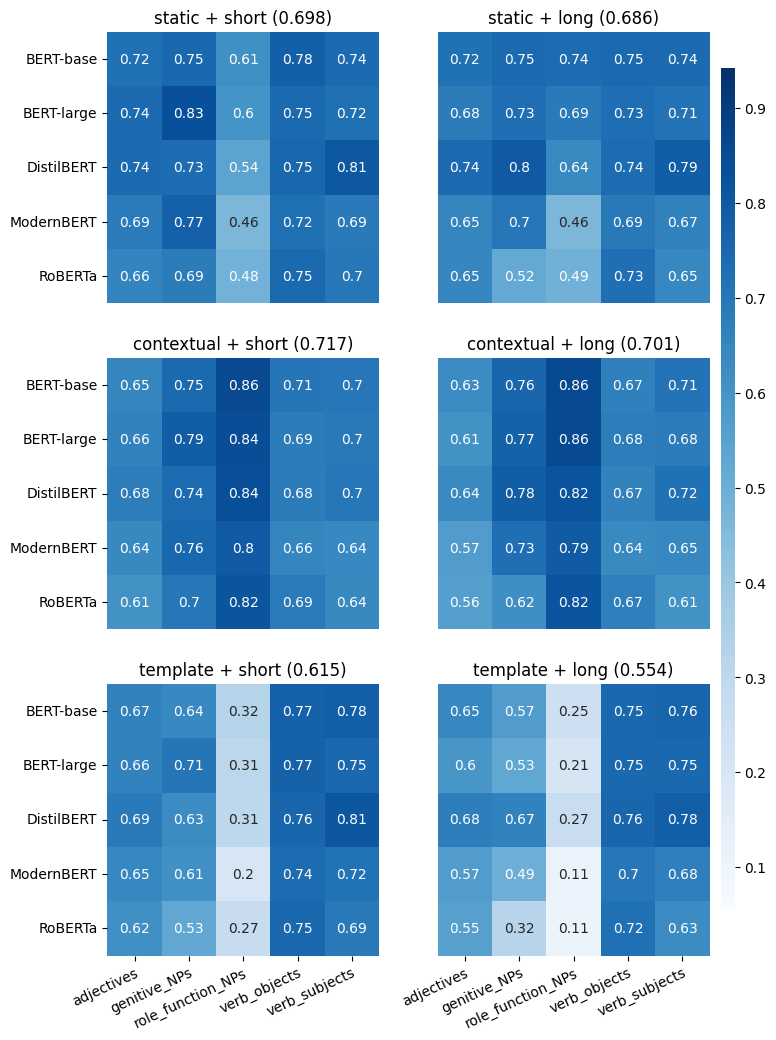

In [ ]:
fig, axes = plt.subplots(3,2, figsize=(9,12))
fig.subplots_adjust(wspace=-0.1)
axes = axes.flatten()
cbar_ax = fig.add_axes([0.86, 0.15, 0.015, 0.7])  # separate colorbar axis
#fig.subplots_adjust(wspace=0, right=0.93)  # leave room for colorbar

vmin = scores_no_log["performance"].min()
vmax = scores_no_log["performance"].max()
for i, (ax, context) in enumerate(zip(axes, context_order)):

  heatmap_data = (
      scores_no_log[(scores_no_log["context"] == context)]
      .groupby(["mlm_abb", "ling_category"], observed=True)["performance"]
      .mean()
      .unstack("ling_category")
  )
  group_average = heatmap_data.mean(axis=None)
  print(f"Group {context} average: {group_average}")
  sns.heatmap(heatmap_data, cmap="Blues", ax=ax, vmin=vmin, vmax=vmax, square=True, annot=True,
              cbar=(i == scores_no_log.context.nunique()-1), cbar_ax=cbar_ax if (i == scores_per_experiment.context.nunique()-1) else None,
              )
  ax.set_title(f"{context} ({group_average:.3f})")
  ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right", rotation_mode="anchor")
  if i % 2 != 0:
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.set_yticklabels([])

  if i not in (4, 5):
    ax.set_xticks([])
    ax.set_xlabel("")
    ax.set_xticklabels([])
  ax.set_xlabel("")
  ax.set_ylabel("")
#fig.supxlabel("Linguistic categories")
#plt.suptitle("Effect of context")
plt.savefig("context_heatmap_fixed.pdf", bbox_inches="tight")
plt.show()

## Compare all experiments to Atypical Animacy results

Results from Lonke (2025).

In [ ]:
aa_results = {
    # Macro F1 Score
    "verb_subjects": 0.862,
    "verb_objects": 0.804,
    "adjectives": 0.704,
    # Accuracy
    "role_function_NPs": 0.470,
    "genitive_NPs": 0.783
}

aa_res = pd.Series(aa_results, name="performance")
display(aa_res)
aa_avg = aa_res.mean().round(3)

print("Average:", aa_avg)

,performance
verb_subjects,0.862
verb_objects,0.804
adjectives,0.704
role_function_NPs,0.470
genitive_NPs,0.783


Average: 0.725


In [ ]:
average_per_experiment = scores_per_experiment.groupby("experiment", observed=True)["performance"].mean()

In [ ]:
# How many experiments are better than Atypical Animacy on average?
average_per_experiment[average_per_experiment > aa_avg]

,performance
experiment,
hard_bert-base-uncased_all-MiniLM-L6-v2_k100_0_0,0.751139
hard_bert-base-uncased_all-MiniLM-L6-v2_k100_0_1,0.770377
hard_bert-base-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.757208
hard_bert-base-uncased_all-MiniLM-L6-v2_k100_contextual_1,0.759497
hard_bert-base-uncased_all-MiniLM-L6-v2_k10_0_0,0.735976
...,...
soft_roberta-base_all-MiniLM-L6-v2_k100_contextual_0,0.750380
soft_roberta-base_all-MiniLM-L6-v2_k10_contextual_0,0.747058
soft_roberta-base_all-MiniLM-L6-v2_k150_contextual_0,0.750901


In [ ]:
# How big of a proportion of the experiments surpasses Atypical Animacy?
202/1080

0.18703703703703703

In [ ]:
# Does the final method surpass Atypical Animacy?
average_per_experiment.loc['soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_0_0']

np.float64(0.7604647983595352)

In [ ]:
average_per_experiment.sort_values()

,performance
experiment,
hard_roberta-base_all-MiniLM-L6-v2_k10_2_1,0.423195
hard_roberta-base_all-MiniLM-L6-v2_k100_2_1,0.423894
hard_roberta-base_all-MiniLM-L6-v2_k150_2_1,0.423894
hard_roberta-base_all-MiniLM-L6-v2_k50_2_1,0.425963
soft_roberta-base_all-MiniLM-L6-v2_k1_2_1,0.431329
...,...
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.785012
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_0_1,0.786603
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_0_1,0.786603


## Compare the results of BPE-fixed AnthroScore

In [ ]:
anthroset = pd.read_csv("anthroset_with_scores (1).csv")
anthroset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     600 non-null    object 
 1   previous_sentence      597 non-null    object 
 2   current_sentence       600 non-null    object 
 3   masked_sentence        600 non-null    object 
 4   next_sentence          537 non-null    object 
 5   AI_phrase              600 non-null    object 
 6   masked_phrase          600 non-null    object 
 7   AI_entity              600 non-null    object 
 8   component              600 non-null    object 
 9   expectations           600 non-null    int64  
 10  masked_sentence_bert   600 non-null    object 
 11  long_context           600 non-null    object 
 12  long_context_bert      600 non-null    object 
 13  ling_category          600 non-null    object 
 14  anthroscore_orig       600 non-null    float64
 15  anthro

In [ ]:
anthroset["anthroscore_orig_pred"] = (anthroset["anthroscore_orig"] > 0).astype(int)
anthroset["anthroscore_bpe_pred"] = (anthroset["anthroscore_bpe"] > 0).astype(int)

anthroset["anthroscore_orig_correct"] = (anthroset["anthroscore_orig_pred"] == anthroset["expectations"]).astype(int)
anthroset["anthroscore_bpe_correct"] = (anthroset["anthroscore_bpe_pred"] == anthroset["expectations"]).astype(int)

In [ ]:
anthroset.columns

Index(['id', 'previous_sentence', 'current_sentence', 'masked_sentence',
       'next_sentence', 'AI_phrase', 'masked_phrase', 'AI_entity', 'component',
       'expectations', 'masked_sentence_bert', 'long_context',
       'long_context_bert', 'ling_category', 'anthroscore_orig',
       'anthroscore_bpe', 'anthroscore_orig_long', 'anthroscore_bpe_long',
       'anthroscore_orig_pred', 'anthroscore_bpe_pred',
       'anthroscore_orig_correct', 'anthroscore_bpe_correct'],
      dtype='object')

In [ ]:
orig = anthroset[["id", "ling_category", "expectations", "anthroscore_orig_pred"]].copy()
orig = orig.rename(columns={"anthroscore_orig_pred": "pred"})
orig = orig[orig["expectations"] != 2]

orig

,id,ling_category,expectations,pred
21,3_acl_14_42916_4,adjectives,0,0
22,3_arx_2410.02110_2160311_2,adjectives,0,0
23,3_acl_877_29913_4,adjectives,0,0
24,3_arx_2405.20189_2077401_0,adjectives,0,1
25,3_acl_18_54647_0,adjectives,0,1
...,...,...,...,...
595,1_arx_2010.09890_1366220_2,verb_subjects,1,0
596,1_acl_1477_40886_4,verb_subjects,1,0
597,1_arx_2303.09387_1809184_9,verb_subjects,1,0
598,1_arx_2212.01681_1757858_4,verb_subjects,1,0


In [ ]:
orig_scored = (
    orig.groupby("ling_category", observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)
orig_scored

/tmp/ipykernel_643/478043051.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


,ling_category,performance
0,adjectives,0.441868
1,genitive_NPs,0.283333
2,role_function_NPs,0.185714
3,verb_objects,0.545556
4,verb_subjects,0.518519


In [ ]:
orig_scored.performance.mean()

np.float64(0.3949979933596855)

In [ ]:
bpe = anthroset[["id", "ling_category", "expectations", "anthroscore_bpe_pred"]].copy()
bpe = bpe.rename(columns={"anthroscore_bpe_pred": "pred"})
bpe = bpe[bpe["expectations"] != 2]

bpe

,id,ling_category,expectations,pred
21,3_acl_14_42916_4,adjectives,0,0
22,3_arx_2410.02110_2160311_2,adjectives,0,0
23,3_acl_877_29913_4,adjectives,0,0
24,3_arx_2405.20189_2077401_0,adjectives,0,0
25,3_acl_18_54647_0,adjectives,0,1
...,...,...,...,...
595,1_arx_2010.09890_1366220_2,verb_subjects,1,0
596,1_acl_1477_40886_4,verb_subjects,1,1
597,1_arx_2303.09387_1809184_9,verb_subjects,1,0
598,1_arx_2212.01681_1757858_4,verb_subjects,1,0


In [ ]:
bpe_scored = (
    bpe.groupby("ling_category", observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)
bpe_scored

/tmp/ipykernel_643/249060776.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


,ling_category,performance
0,adjectives,0.483397
1,genitive_NPs,0.233333
2,role_function_NPs,0.342857
3,verb_objects,0.582086
4,verb_subjects,0.589138


In [ ]:
bpe_mean = bpe_scored.performance.mean()
bpe_mean

np.float64(0.4461623599620143)

In [ ]:
average_per_experiment[average_per_experiment > bpe_mean]

,performance
experiment,
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,0.707702
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_1,0.709765
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_2_0,0.511495
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_2_1,0.461107
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_contextual_0,0.710977
...,...
soft_roberta-base_modernbert-embed-base_k5_0_1,0.538298
soft_roberta-base_modernbert-embed-base_k5_2_0,0.581442
soft_roberta-base_modernbert-embed-base_k5_2_1,0.485600


In [ ]:
# How many experiments perform better than BPE-fixed method?
1069/1080

0.9898148148148148